In [37]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf

In [38]:
plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    "text.latex.preamble": r"\usepackage{amsmath} \usepackage{amssymb}"
})

In [39]:
def compute_log_likelihood(z, max_param):
    gaussian_term = 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((z - hidden_params_vals) / sigma) ** 2)
    normalization = 1 / 2 * (1 + erf((hidden_params_vals - selection_cut) / (sigma * np.sqrt(2))))

    gaussian_term_with_selection = gaussian_term / normalization

    integrand = gaussian_term_with_selection[:, None] * 1 / max_param[None, :] * np.heaviside(max_param[None, :] - hidden_params_vals[:, None], 0)
    likelihood = np.trapz(integrand, hidden_params_vals, axis=0)

    log_likelihood = np.log(likelihood)

    log_likelihood = np.where(np.isfinite(log_likelihood), log_likelihood, -np.inf)
    log_likelihood = np.where(np.isinf(log_likelihood), -100, log_likelihood)

    return log_likelihood

In [40]:
sigma = 1
selection_cut = 4.0
true_max = 10.3
hidden_params_vals = np.linspace(0, 20, 10_000)

# generate uniform random draws above cut
num_samples = 100
hidden_params = np.random.uniform(0, true_max, num_samples)
observed_data = hidden_params + np.random.normal(0, sigma, num_samples)

mask = observed_data > selection_cut
observed_data = observed_data[mask]

print(f"Number of observed data points: {len(observed_data)}")

Number of observed data points: 72


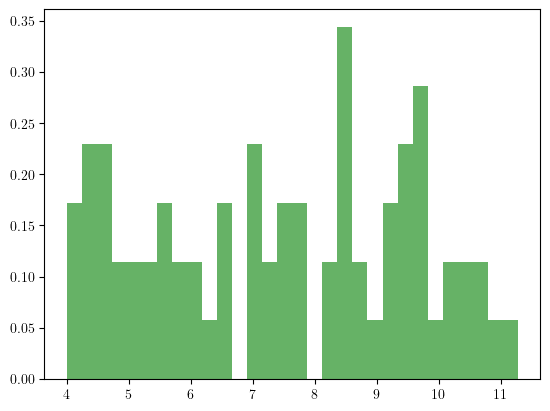

In [41]:
plt.hist(observed_data, bins=30, density=True, alpha=0.6, color='g');

/var/folders/6k/xt_kj55n7ds1y0cck0fxs9zh0000gp/T/ipykernel_24444/2266038769.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  likelihood = np.trapz(integrand, hidden_params_vals, axis=0)


Text(0, 0.5, 'Likelihood')

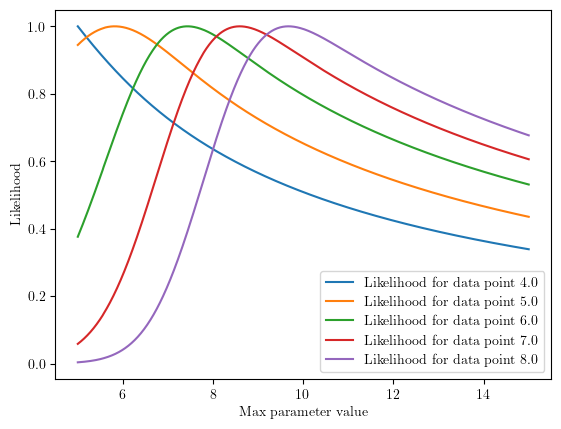

In [42]:
max_param_vals = np.linspace(5, 15, 1000)

for data_point in [selection_cut, selection_cut+1, selection_cut+2, selection_cut+3, selection_cut+4]:
    log_likelihood_test = compute_log_likelihood(data_point, max_param=max_param_vals)
    plt.plot(max_param_vals, np.exp(log_likelihood_test - np.max(log_likelihood_test)), label=f'Likelihood for data point {data_point}')
plt.legend()
plt.xlabel('Max parameter value')
plt.ylabel('Likelihood')

In [50]:
max_param_vals = np.linspace(5, 13.4, 1000)
log_likelihood_vals = [compute_log_likelihood(o, max_param=max_param_vals) for o in observed_data]
log_likelihood_vals = np.array(log_likelihood_vals)
total_log_likelihood = np.sum(log_likelihood_vals, axis=0)

/var/folders/6k/xt_kj55n7ds1y0cck0fxs9zh0000gp/T/ipykernel_24444/2266038769.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  likelihood = np.trapz(integrand, hidden_params_vals, axis=0)


<>:5: SyntaxWarning: invalid escape sequence '\{'
<>:5: SyntaxWarning: invalid escape sequence '\{'
/var/folders/6k/xt_kj55n7ds1y0cck0fxs9zh0000gp/T/ipykernel_24444/2267968851.py:5: SyntaxWarning: invalid escape sequence '\{'
  plt.ylabel('$p(M | \{Z\})$', fontsize=16)


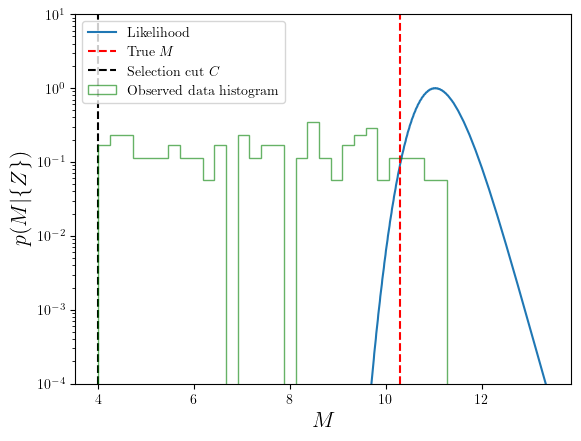

In [51]:
plt.plot(max_param_vals, np.exp(total_log_likelihood - np.max(total_log_likelihood)), label='Likelihood')
plt.yscale('log')
plt.ylim(1e-4, 10)
plt.xlabel('$M$', fontsize=16)
plt.ylabel('$p(M | \{Z\})$', fontsize=16)
plt.axvline(true_max, color='r', linestyle='--', label='True $M$')
plt.axvline(selection_cut, color='k', linestyle='--', label='Selection cut $C$')
plt.hist(observed_data, bins=30, density=True, alpha=0.6, color='g', label='Observed data histogram', histtype='step')
plt.legend()
plt.savefig('plots/selection_effect_with_noise_likelihood.pdf', bbox_inches='tight')